## Hydrogen Model

In [1]:
import pandas as pd
import numpy as np
import pylab as plt

import pypsa

# Import the public function from the package you completed
from energy_model import model_run

# input database folder
db_dir = 'input_databases//default_hydrogen'

# model years
years = [2020,2030,2040,2050]

# intra-year temporal resolution
t_res = 15 # hours

# discount rates
rt = 0.07 # technical discount rate
rs = 0.01 # social discount rate

# passenger cars conversion factor
passenger_cars_cf = 40*0.1  # km/h

In [2]:
# Handy plotting functions

def plot_main_ebs(scen):
    fig, ax = plt.subplots(1,6)
    fig.set_size_inches(20,4)

    for n,c in enumerate(['Residential electricity',
            'Residential heat',
            'Transportation',
            'Industrial machinery',
            'Industrial HTP',
            'Hydrogen']): 
        df = scen.statistics.energy_balance(bus_carrier=c)
        df = df.set_index(df.index.get_level_values(1))
        df.T.plot(kind='bar',stacked='True', rot=0, colormap='tab20',ax=ax[n])
        if c=='Transportation':
            ax[n].set_ylabel('Mvkm')
        else:
            ax[n].set_ylabel('MWh')
        ax[n].set_title(c)

    fig.tight_layout()

def plot_elc_emi(scen):
    fig, ax = plt.subplots(1,5)
    fig.set_size_inches(20,4)

    for n,c in enumerate(['Electricity','CO2 atmosphere', 'CO2 storage']):
        df = scen.statistics.energy_balance(bus_carrier=c)
        df = df.set_index(df.index.get_level_values(1))
        df.T.plot(kind='bar',stacked='True', rot=0, colormap='tab20', ax=ax[n])

        if 'CO2' in c:
            ax[n].set_ylabel('tCO2')
        else:
            ax[n].set_ylabel('MWh')
        ax[n].set_title(c)
        ax[n].legend(bbox_to_anchor=(1,-0.5))

    # Let's add cumulative CO2
    for n,c in enumerate(['CO2 atmosphere', 'CO2 storage']):
        df = scen.statistics.energy_balance(bus_carrier=c).cumsum(axis=1)
        df = df.set_index(df.index.get_level_values(1))
        df.T.plot(kind='bar', stacked=True, colormap='tab20', ax=ax[n+3])
        ax[n+3].set_ylabel('tCO2')
        ax[n+3].set_title(f'Cumulative {c}')
        ax[n+3].legend(bbox_to_anchor=(1,-0.5))

    fig.tight_layout()

In [3]:
hydrogen_only_grey = model_run(db_dir, years, t_res, passenger_cars_cf, rt, rs)

2020
2030
2040
2050


Writing continuous variables.: 100%|██████████| 10/10 [00:00<00:00, 283.44it/s]

Set parameter Username
Set parameter LicenseID to value 2858750
Academic license - for non-commercial use only - expires 2027-08-31


Read LP format model from file C:\Users\rosam\AppData\Local\Temp\linopy-problem-_j_r6w5d.lp
Reading time = 0.45 seconds
obj: 311374 rows, 144926 columns, 729934 nonzeros
Set parameter LogFile to value "results//solver_run.log"
Set parameter LogToConsole to value 0


Model Status: ok
Termination Condition: optimal
Objective value: 69066355224695.03


C:\Users\rosam\AppData\Local\Temp\ipykernel_24812\1405147835.py:49: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


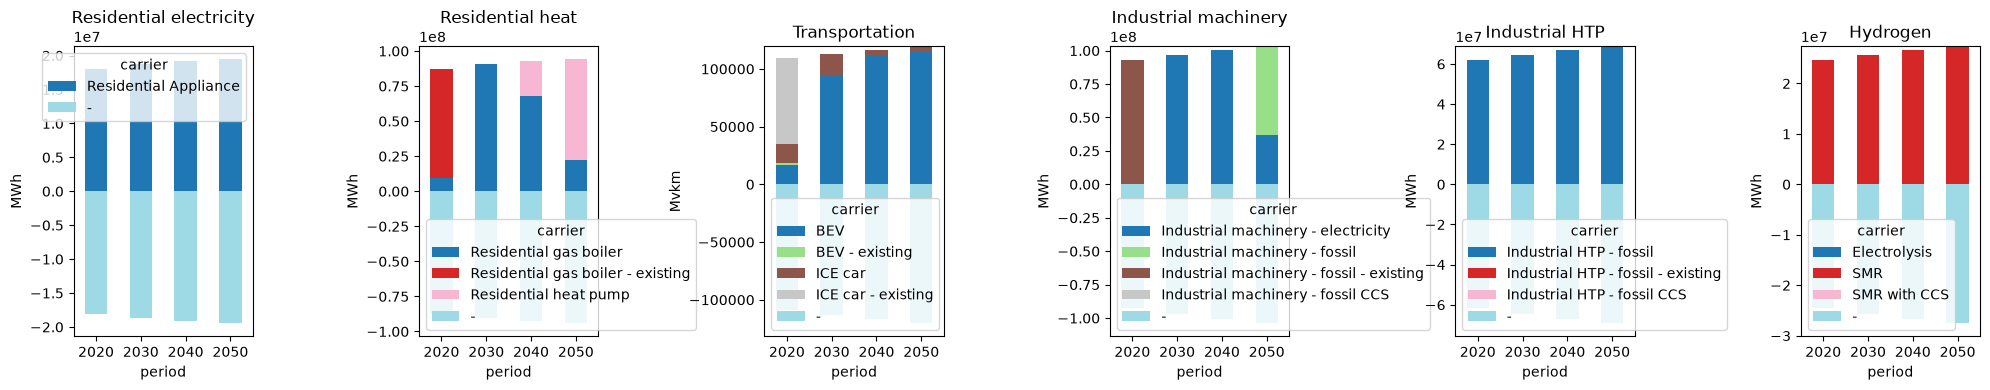

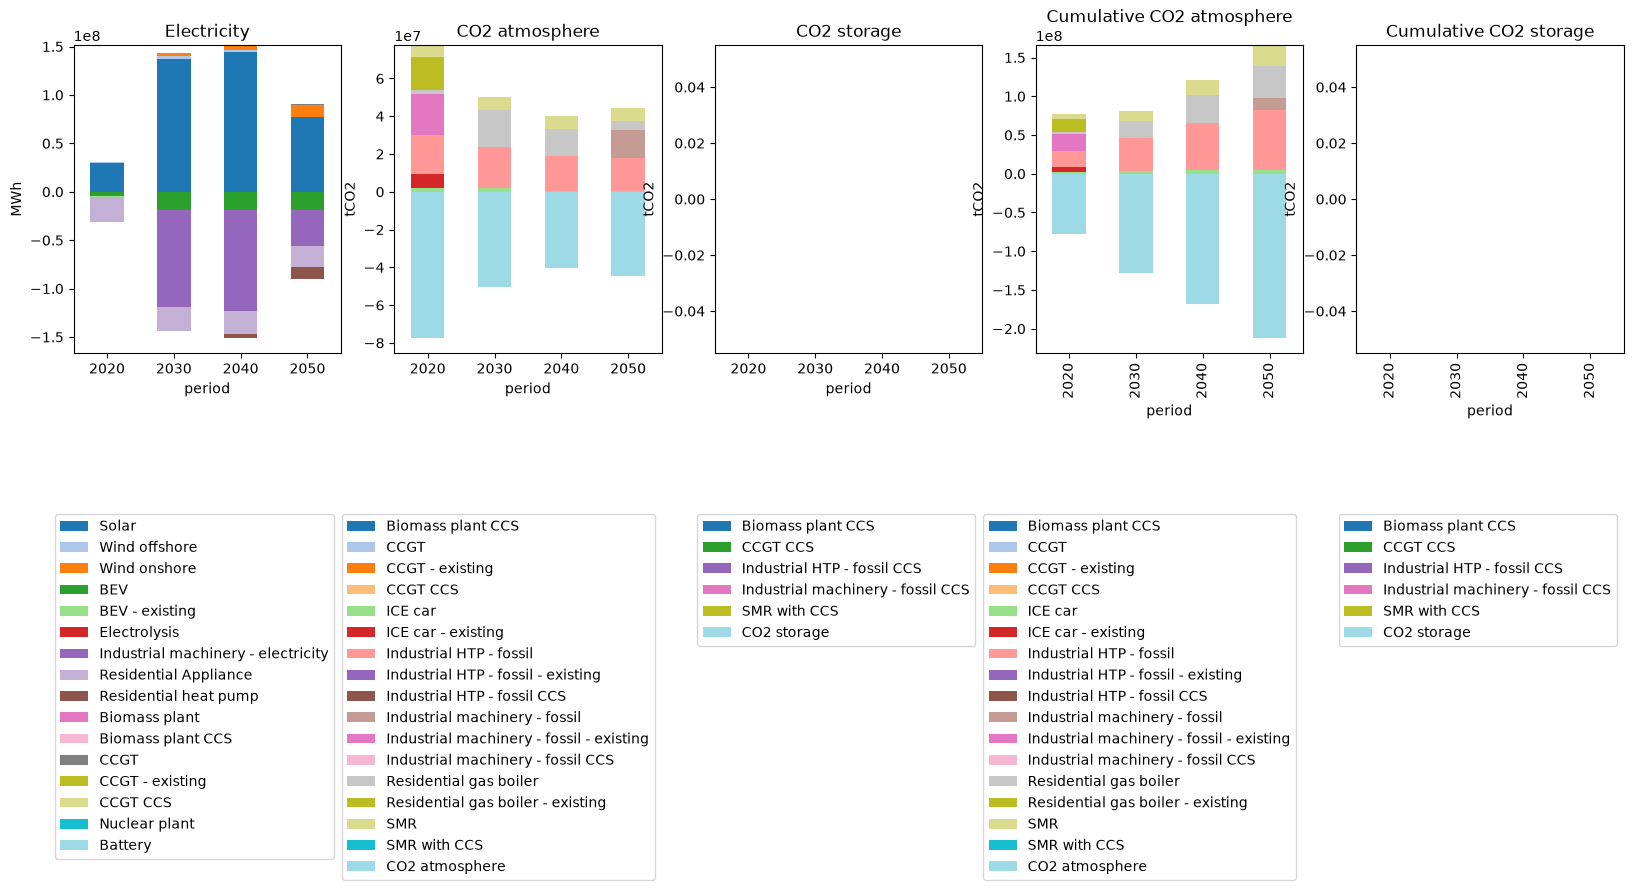

In [4]:
plot_main_ebs(hydrogen_only_grey)
plot_elc_emi(hydrogen_only_grey)
